# Credit Card Fraud Detection
**Author:** Jesly Prosper

## Problem
Card fraud is rare (well under 1% of transactions) but expensive. A model that flags every transaction as genuine would be over 99% "accurate" and completely useless. The goal of this project is to build a model that **catches as much fraud as possible while keeping false alarms low**, and to measure its value in money, not just accuracy.

## Data
The [Kaggle Credit Card Fraud Detection dataset](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud): 284,807 European card transactions over two days, 492 of them fraud. Features `V1` to `V28` are anonymised PCA components; `Time` and `Amount` are raw; `Class` is 1 for fraud.

## Approach
1. Explore the data and the class imbalance
2. Split by **time** (train on earlier transactions, test on later ones), the way a real fraud system is used
3. Compare a baseline, a logistic regression and a gradient-boosted model, both weighted for the imbalance
4. Evaluate with **precision, recall and PR-AUC** instead of accuracy
5. Tune the alert threshold on a validation set and estimate the **money saved**
6. Explain which features drive the model, and check performance stability over time (monitoring)

In [3]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, confusion_matrix, accuracy_score)
RANDOM_STATE = 42
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

## 1. Load the data

In [4]:
import glob
matches = glob.glob('/kaggle/input/**/creditcard.csv', recursive=True) + glob.glob('creditcard.csv') + glob.glob('data/creditcard.csv')
if not matches:
    raise FileNotFoundError("creditcard.csv not found. In the right panel click 'Add Input', search 'creditcardfraud' (by mlg-ulb) and add it.")
path = matches[0]
df = pd.read_csv(path)
print(f'Loaded {len(df):,} transactions from {path}')
df.head()

Loaded 284,807 transactions from /kaggle/input/datasets/jeslypro/creditcard-csv/creditcard.csv


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,...,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,...,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,...,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,...,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,...,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


## 2. Explore the data

In [5]:
fraud_rate = df['Class'].mean()
print(f"Fraud cases: {df['Class'].sum():,} of {len(df):,} ({fraud_rate:.3%})")
print(f"Missing values: {df.isna().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum():,}")
df.groupby('Class')['Amount'].describe()

Fraud cases: 492 of 284,807 (0.173%)
Missing values: 0
Duplicate rows: 1,081


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,"284,315.0000",88.2910,250.1051,0.0000,5.6500,22.0000,77.0500,"25,691.1600"
1,492.0000,122.2113,256.6833,0.0000,1.0000,9.2500,105.8900,"2,125.8700"


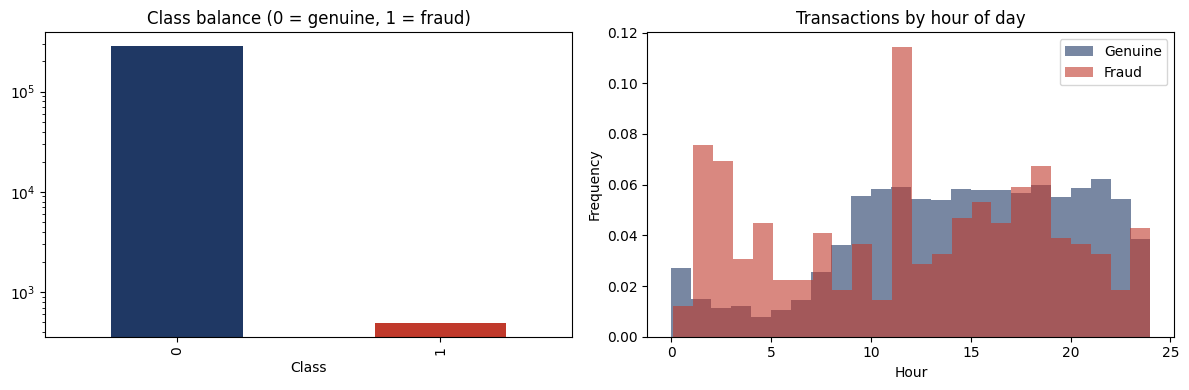

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df['Class'].value_counts().plot.bar(ax=ax[0], color=['#1F3864', '#C0392B'])
ax[0].set_title('Class balance (0 = genuine, 1 = fraud)'); ax[0].set_yscale('log')
for c, col in [(0, '#1F3864'), (1, '#C0392B')]:
    (df.loc[df['Class'] == c, 'Time'] / 3600 % 24).plot.hist(ax=ax[1], bins=24, density=True, alpha=0.6, color=col, label=['Genuine', 'Fraud'][c])
ax[1].set_title('Transactions by hour of day'); ax[1].set_xlabel('Hour'); ax[1].legend()
plt.tight_layout(); plt.show()

**Takeaways:** the classes are extremely imbalanced, so accuracy is misleading. Fraud is relatively more common in the early-morning hours, so hour of day is a useful engineered feature.

## 3. Feature engineering and a time-based split

In [7]:
df = df.drop_duplicates().sort_values('Time').reset_index(drop=True)
df['Hour'] = (df['Time'] / 3600) % 24
df['LogAmount'] = np.log1p(df['Amount'])
features = [f'V{i}' for i in range(1, 29)] + ['LogAmount', 'Hour']

# Earliest 60% of transactions to train, next 20% to validate (tune the threshold), latest 20% to test
n = len(df); i1, i2 = int(n * 0.6), int(n * 0.8)
train, val, test = df.iloc[:i1], df.iloc[i1:i2], df.iloc[i2:]
X_train, y_train = train[features], train['Class']
X_val, y_val = val[features], val['Class']
X_test, y_test = test[features], test['Class']
for name, part in [('Train', train), ('Validation', val), ('Test', test)]:
    print(f"{name:<11} {len(part):>8,} rows   fraud {part['Class'].sum():>4}  ({part['Class'].mean():.3%})")

Train        170,235 rows   fraud  342  (0.201%)
Validation    56,745 rows   fraud   57  (0.100%)
Test          56,746 rows   fraud   74  (0.130%)


## 4. Train models
Both real models are weighted so that each fraud case counts as much as many genuine ones.

In [8]:
models = {
    'Baseline (always genuine)': DummyClassifier(strategy='most_frequent'),
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=2000)),
    'Gradient boosting': HistGradientBoostingClassifier(class_weight='balanced', learning_rate=0.05, max_iter=300,
                                                         max_leaf_nodes=31, l2_regularization=1.0, random_state=RANDOM_STATE),
}
val_scores = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    val_scores[name] = m.predict_proba(X_val)[:, 1]

def summarise(y, p, threshold=0.5):
    pred = (p >= threshold).astype(int)
    return {'Accuracy': accuracy_score(y, pred), 'Precision': precision_score(y, pred, zero_division=0),
            'Recall': recall_score(y, pred), 'F1': f1_score(y, pred, zero_division=0),
            'PR-AUC': average_precision_score(y, p), 'ROC-AUC': roc_auc_score(y, p)}

pd.DataFrame({k: summarise(y_val, v) for k, v in val_scores.items()}).T

,Accuracy,Precision,Recall,F1,PR-AUC,ROC-AUC
Baseline (always genuine),0.9990,0.0000,0.0000,0.0000,0.0010,0.5000
Logistic regression,0.9589,0.0214,0.8947,0.0419,0.7601,0.9720
Gradient boosting,0.9971,0.2323,0.8070,0.3608,0.7432,0.9459


The baseline scores very high **accuracy** while catching zero fraud, which shows why accuracy is the wrong metric here. **PR-AUC** (average precision) is the fairest single number for rare-event problems.

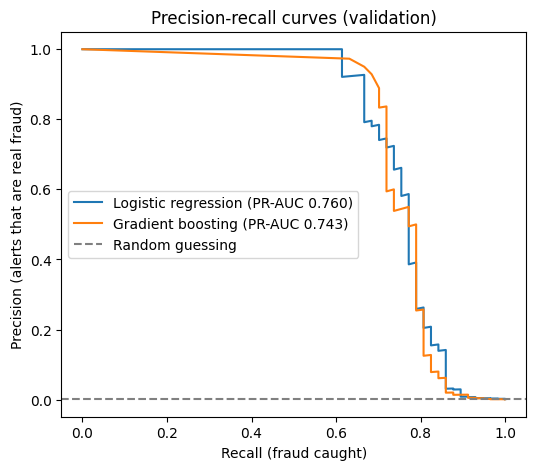

In [9]:
plt.figure(figsize=(6, 5))
for name in ['Logistic regression', 'Gradient boosting']:
    p, r, _ = precision_recall_curve(y_val, val_scores[name])
    plt.plot(r, p, label=f"{name} (PR-AUC {average_precision_score(y_val, val_scores[name]):.3f})")
plt.axhline(y_val.mean(), ls='--', c='grey', label='Random guessing')
plt.xlabel('Recall (fraud caught)'); plt.ylabel('Precision (alerts that are real fraud)')
plt.title('Precision-recall curves (validation)'); plt.legend(); plt.show()

## 5. Choose the alert threshold by cost
A missed fraud costs roughly the transaction amount; a false alarm costs an analyst review and customer friction. The dataset amounts are in euros. I assume **€5 per false alarm** and pick the threshold that minimises total cost on the validation set.

Best model on validation: Logistic regression


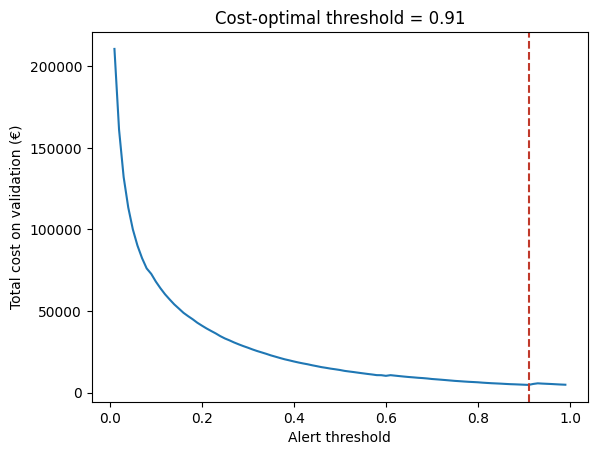

In [10]:
REVIEW_COST = 5.0
best = max(['Logistic regression', 'Gradient boosting'], key=lambda k: average_precision_score(y_val, val_scores[k]))
print('Best model on validation:', best)

def total_cost(y, p, amount, t):
    pred = p >= t
    missed = amount[(y == 1) & ~pred].sum()
    false_alarms = ((y == 0) & pred).sum()
    return missed + REVIEW_COST * false_alarms

thresholds = np.linspace(0.01, 0.99, 99)
costs = [total_cost(y_val.values, val_scores[best], val['Amount'].values, t) for t in thresholds]
best_t = thresholds[int(np.argmin(costs))]
plt.plot(thresholds, costs); plt.axvline(best_t, ls='--', c='#C0392B')
plt.xlabel('Alert threshold'); plt.ylabel('Total cost on validation (€)'); plt.title(f'Cost-optimal threshold = {best_t:.2f}'); plt.show()

## 6. Final results on the unseen test period

In [11]:
final = models[best]
p_test = final.predict_proba(X_test)[:, 1]
res = summarise(y_test, p_test, best_t)
cm = confusion_matrix(y_test, (p_test >= best_t).astype(int))
tn, fp, fn, tp = cm.ravel()
no_model_cost = test.loc[test['Class'] == 1, 'Amount'].sum()
model_cost = total_cost(y_test.values, p_test, test['Amount'].values, best_t)
print(f"Model: {best}   threshold: {best_t:.2f}")
for k, v in res.items(): print(f"{k:<10} {v:.3f}")
print(f"\nFraud caught: {tp} of {tp + fn}   false alarms: {fp:,} of {tn + fp:,} genuine transactions")
print(f"Fraud losses with no model: €{no_model_cost:,.0f}")
print(f"Cost with model (missed fraud + reviews): €{model_cost:,.0f}")
print(f"Estimated saving: €{no_model_cost - model_cost:,.0f} ({(no_model_cost - model_cost) / no_model_cost:.0%})")

Model: Logistic regression   threshold: 0.91
Accuracy   0.995
Precision  0.185
Recall     0.851
F1         0.304
PR-AUC     0.746
ROC-AUC    0.983

Fraud caught: 63 of 74   false alarms: 278 of 56,672 genuine transactions
Fraud losses with no model: €7,728
Cost with model (missed fraud + reviews): €3,757
Estimated saving: €3,970 (51%)


## 7. What drives the model?
Permutation importance: how much PR-AUC drops when each feature is shuffled.

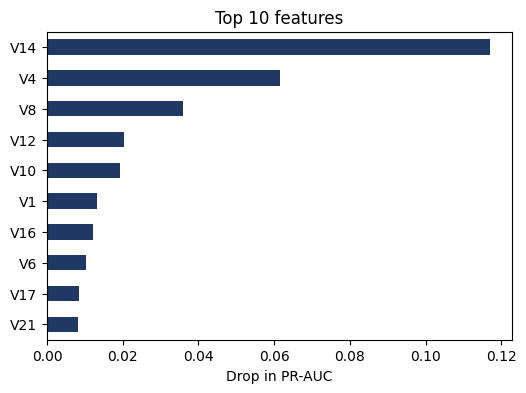

In [12]:
sample = X_test.copy(); sample['Class'] = y_test.values
sample = pd.concat([sample[sample['Class'] == 1], sample[sample['Class'] == 0].sample(min(20000, (sample['Class'] == 0).sum()), random_state=RANDOM_STATE)])
imp = permutation_importance(final, sample[features], sample['Class'], scoring='average_precision', n_repeats=5, random_state=RANDOM_STATE)
top = pd.Series(imp.importances_mean, index=features).sort_values().tail(10)
top.plot.barh(color='#1F3864', figsize=(6, 4)); plt.title('Top 10 features'); plt.xlabel('Drop in PR-AUC'); plt.show()

## 8. Monitoring: is performance stable over time?
In production, fraud patterns drift. Splitting the test period into chunks shows whether performance holds up, which is how a deployed model would be monitored.

In [13]:
chunks = np.array_split(np.arange(len(test)), 4)
rows = []
for i, idx in enumerate(chunks, 1):
    y, p = y_test.iloc[idx], p_test[idx]
    if y.sum() > 0:
        pred = p >= best_t
        rows.append({'Period': i, 'Transactions': len(idx), 'Fraud': int(y.sum()),
                     'Recall': recall_score(y, pred), 'Precision': precision_score(y, pred, zero_division=0)})
pd.DataFrame(rows)

,Period,Transactions,Fraud,Recall,Precision
0,1,14187,22,0.9545,0.2658
1,2,14187,30,0.8333,0.2778
2,3,14186,11,0.9091,0.1190
3,4,14186,11,0.6364,0.0795


## 9. Conclusions and next steps
**Results on the unseen test period (latest 20% of transactions):**
- The class-weighted **logistic regression** had the best PR-AUC on validation (0.760 vs 0.743 for gradient boosting) and was selected.
- It caught **63 of 74 frauds (85% recall)** with a PR-AUC of **0.746** and ROC-AUC of **0.983**, while flagging only **278 of 56,672 genuine transactions (0.5%)**.
- With a cost-based threshold (missed fraud amount plus €5 per false alarm), estimated fraud losses fell from **€7,728 to €3,757, a 51% saving**.
- The baseline scored 99.9% accuracy while catching no fraud at all, which shows why accuracy is the wrong metric.

**Monitoring:** recall fell from 95% in the first test period to 64% in the last, a sign of **drift**. In production this would trigger investigation and retraining.

**Next steps:** add behavioural features (spending velocity per card, time since last transaction) when card IDs are available; tune the gradient-boosted model and try calibrated probabilities; set up drift alerts on recall and alert volume; retrain on a rolling window as fraud patterns change.